a) Construya una señal cuadrada periódica, definiendo su frecuencia fundamental, amplitud y
número de muestras.

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

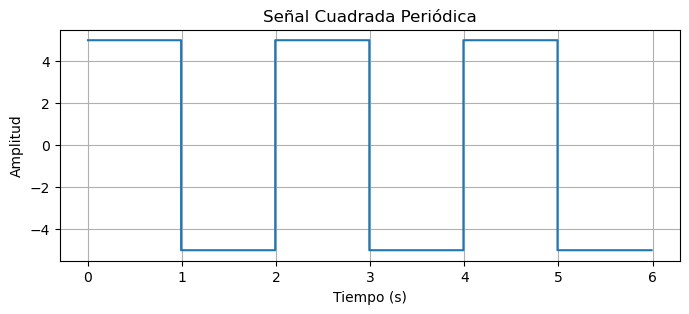

In [67]:

A = 5.0          # Amplitud
f0 = 0.5         # Frecuencia fundamental en Hz
fs = 100.0       # Frecuencia de muestreo en Hz
N = 600         # Número total de muestras

# N muestras divididas por la frecuencia de muestreo nos da el tiempo total
t = np.arange(N) / fs

senal_cuadrada = A * signal.square(2 * np.pi * f0 * t)

plt.figure(figsize=(8, 3))
plt.plot(t, senal_cuadrada, drawstyle='steps-pre')
plt.title('Señal Cuadrada Periódica')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()

b) Construya una señal triangular periódica, con la misma frecuencia fundamental, amplitud y
número de muestras que la señal anterior.

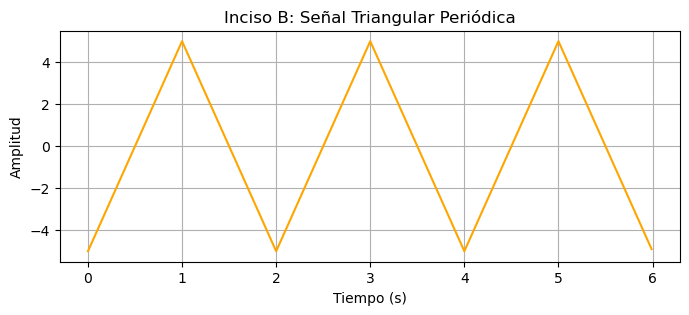

In [68]:
# Usamos signal.sawtooth con width=0.5 para hacerla simétrica
senal_triangular = A * signal.sawtooth(2 * np.pi * f0 * t, width=0.5)


plt.figure(figsize=(8, 3))
plt.plot(t, senal_triangular, color='orange')
plt.title('Inciso B: Señal Triangular Periódica')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()

d) Cree una función que reciba una señal periódica, y devuelva sus coeficientes de la serie de Fourier
(forma exponencial), calculados mediante NumPy.

In [69]:
def calcular_coeficientes_fourier(senal):
    # Obtenemos la cantidad de muestras de la señal que ingrese
    num_muestras = len(senal)
    
    # np.fft.fft calcula el espectro. Lo dividimos por num_muestras para escalar los valores y obtener los coeficientes C_k exactos de la serie.
    c_k = np.fft.fft(senal) / num_muestras
    
    return c_k


e) Aplique la función anterior a la señal cuadrada y a la señal triangular, y obtenga sus respectivos
coeficientes.

In [70]:
# Coeficientes para la señal cuadrada
ck_cuadrada = calcular_coeficientes_fourier(senal_cuadrada)

# Coeficientes para la señal triangular
ck_triangular = calcular_coeficientes_fourier(senal_triangular)


print("Primeros 5 coeficientes C_k (Señal Cuadrada):")
print(np.round(ck_cuadrada[:5], 3))

print("\nPrimeros 5 coeficientes C_k (Señal Triangular):")
print(np.round(ck_triangular[:5], 3))

Primeros 5 coeficientes C_k (Señal Cuadrada):
[ 0.  +0.j    -0.  +0.j     0.  +0.j     0.05-3.183j  0.  +0.j   ]

Primeros 5 coeficientes C_k (Señal Triangular):
[ 0.   +0.j  0.   -0.j  0.   +0.j -2.027-0.j -0.   -0.j]


f) Cree una función que reciba un conjunto de coeficientes de Fourier y grafique el espectro de
magnitud y el espectro de fase correspondientes.

In [71]:
def graficar_espectros(ck, freq_muestreo=1.0):

    N_muestras = len(ck)
    
    freqs = np.fft.fftshift(np.fft.fftfreq(N_muestras, d=1/freq_muestreo))
    ck_centrado = np.fft.fftshift(ck)
    
    # Obtenemos magnitud y fase
    magnitud = np.abs(ck_centrado)
    fase = np.angle(ck_centrado)
    
    # hacer cero la fase donde la magnitud es prácticamente nula para no graficar ruido de redondeo numérico de Python
    fase[magnitud < 1e-10] = 0.0 
    

    plt.figure(figsize=(10, 6))
    
    # 1. Espectro de Magnitud
    plt.subplot(2, 1, 1)
    plt.stem(freqs, magnitud)
    plt.title('Espectro de Magnitud')
    plt.ylabel('|C_k| (Amplitud)')
    plt.grid(True)
    
    # 2. Espectro de Fase
    plt.subplot(2, 1, 2)
    plt.stem(freqs, fase)
    plt.title('Espectro de Fase')
    plt.xlabel('Frecuencia (Hz)')
    plt.ylabel('Fase (Radianes)')
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


g) Grafique los espectros de magnitud y fase de la señal cuadrada y de la señal triangular.

Espectros de la Señal Cuadrada:


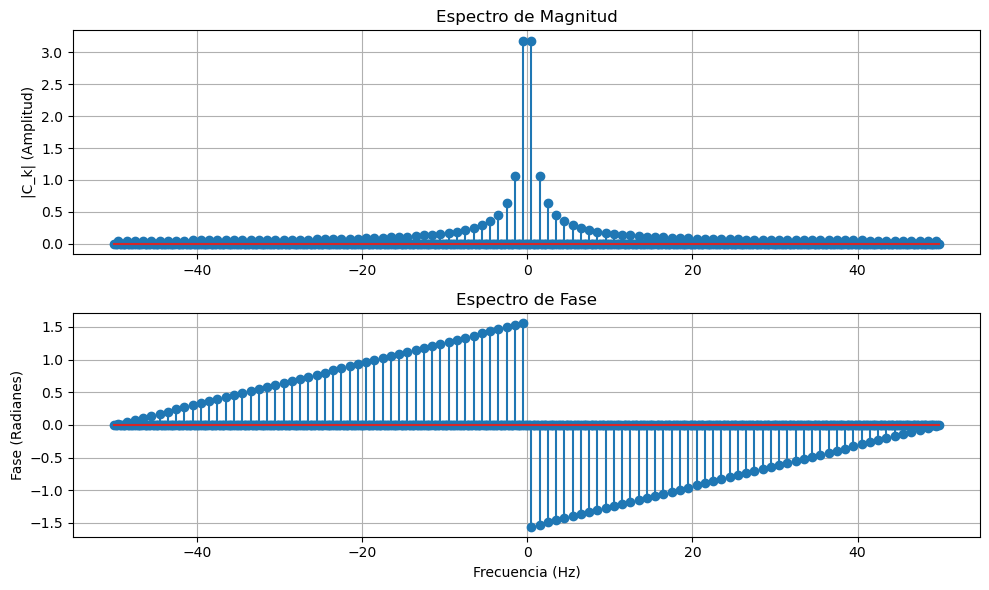

Espectros de la Señal Triangular:


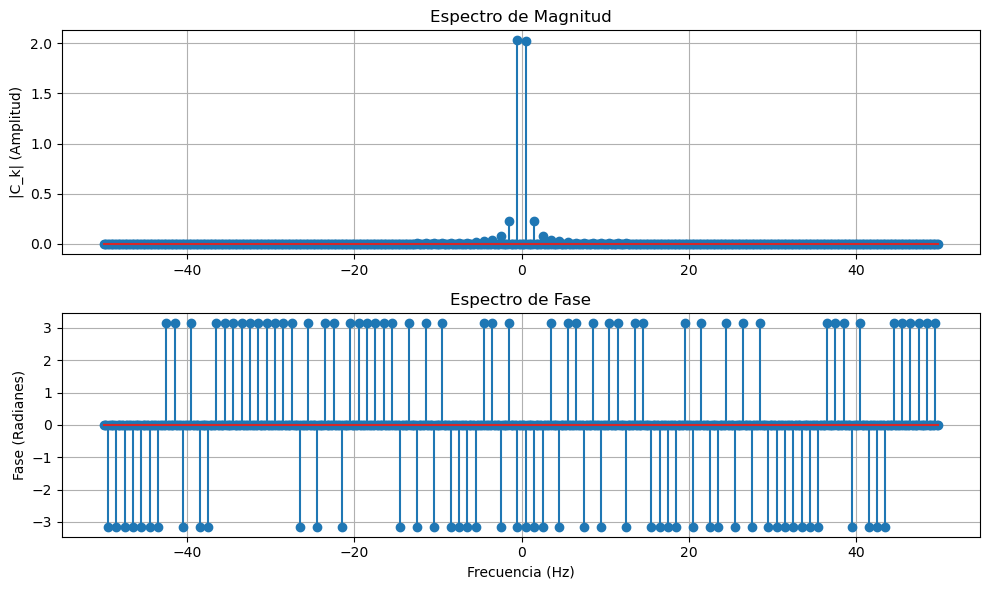

In [72]:
# Espectros de la Señal Cuadrada
print("Espectros de la Señal Cuadrada:")
graficar_espectros(ck_cuadrada, freq_muestreo=fs)

# Espectros de la Señal Triangular
print("Espectros de la Señal Triangular:")
graficar_espectros(ck_triangular, freq_muestreo=fs)

h) Cree una función que reconstruya una señal a partir de una suma de senos (armónicos), recibiendo como parámetros los coeficientes de Fourier y el número de armónicos a utilizar.

In [73]:
def reconstruir_senal(ck, num_armonicos, tiempo, freq_fund):

    senal_reconstruida = np.full_like(tiempo, ck[0].real)
    
    # Sumamos cada armónico desde k=1 hasta num_armonicos
    for k in range(1, num_armonicos + 1):
        magnitud = np.abs(ck[k])
        fase = np.angle(ck[k])
        
        # Forma trigonométrica de la Serie de Fourier:
        # 2 * |C_k| * cos(2 * pi * k * f0 * t + fase)
        armonico = 2 * magnitud * np.cos(2 * np.pi * k * freq_fund * tiempo + fase)
        
        # Añadimos el armónico a la sumatoria total
        senal_reconstruida += armonico
        
    return senal_reconstruida


In [74]:
def reconstruir_senal(ck, num_armonicos, tiempo, freq_fund):

    # Calculamos la resolución de frecuencia real (delta_f)
    fs_calc = 1 / (tiempo[1] - tiempo[0])
    delta_f = fs_calc / len(tiempo)
    

    senal_reconstruida = np.full_like(tiempo, ck[0].real)
    
    for k in range(1, num_armonicos + 1):
        # Frecuencia exacta de este armónico (ej. 0.5, 1.0, 1.5...)
        freq_k = k * freq_fund
        idx = int(round(freq_k / delta_f))
        
        # Verificamos no salirnos del espectro útil
        if idx < len(ck) // 2:
            magnitud = np.abs(ck[idx])
            fase = np.angle(ck[idx])
            
            # Reconstruimos la senoidal
            armonico = 2 * magnitud * np.cos(2 * np.pi * freq_k * tiempo + fase)
            senal_reconstruida += armonico
            
    return senal_reconstruida

i) Reconstruya la señal cuadrada y la señal triangular utilizando N = 1, 3, 5, 20 y 50 armónicos, y grafique cada reconstrucción junto con la señal original.

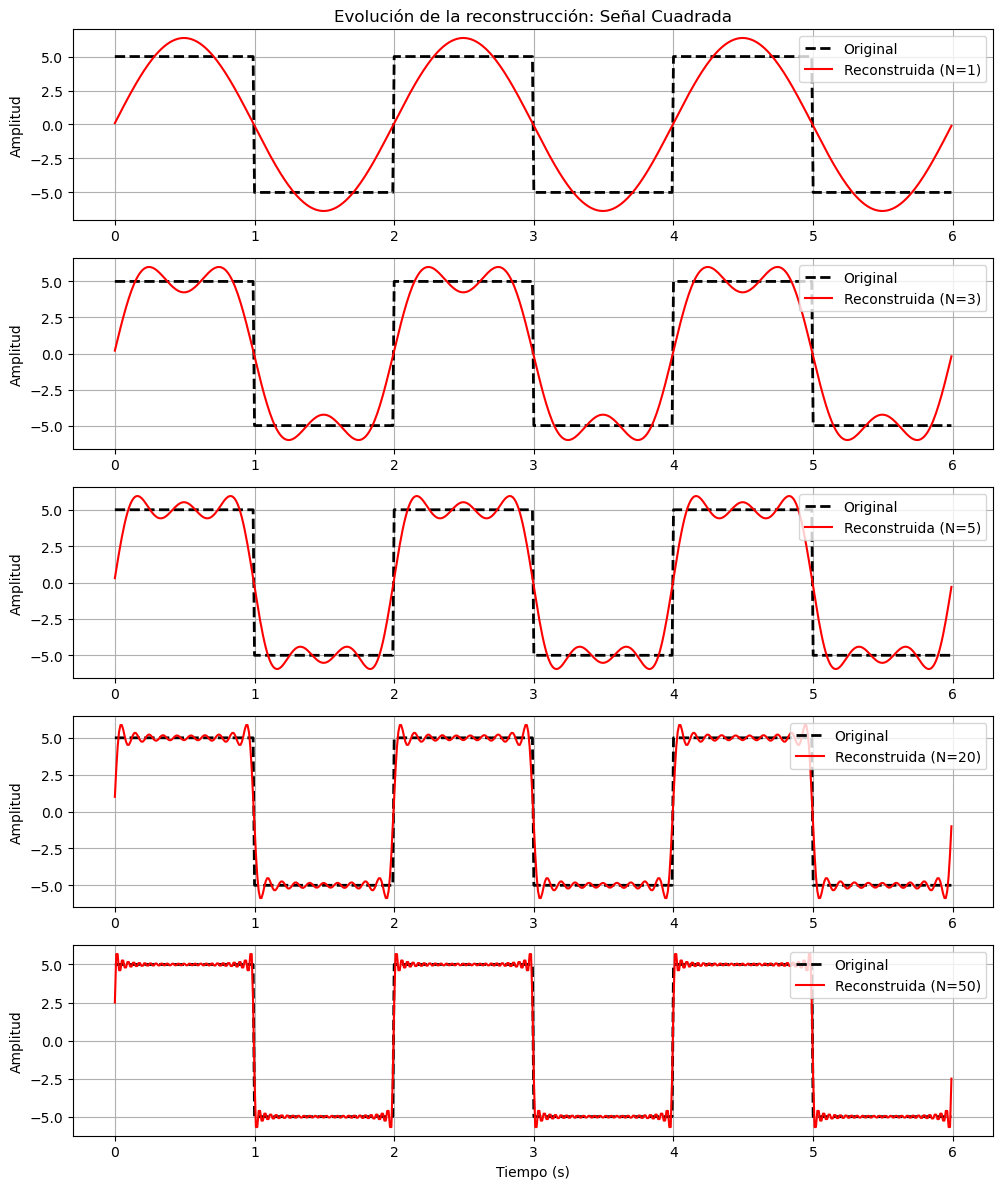

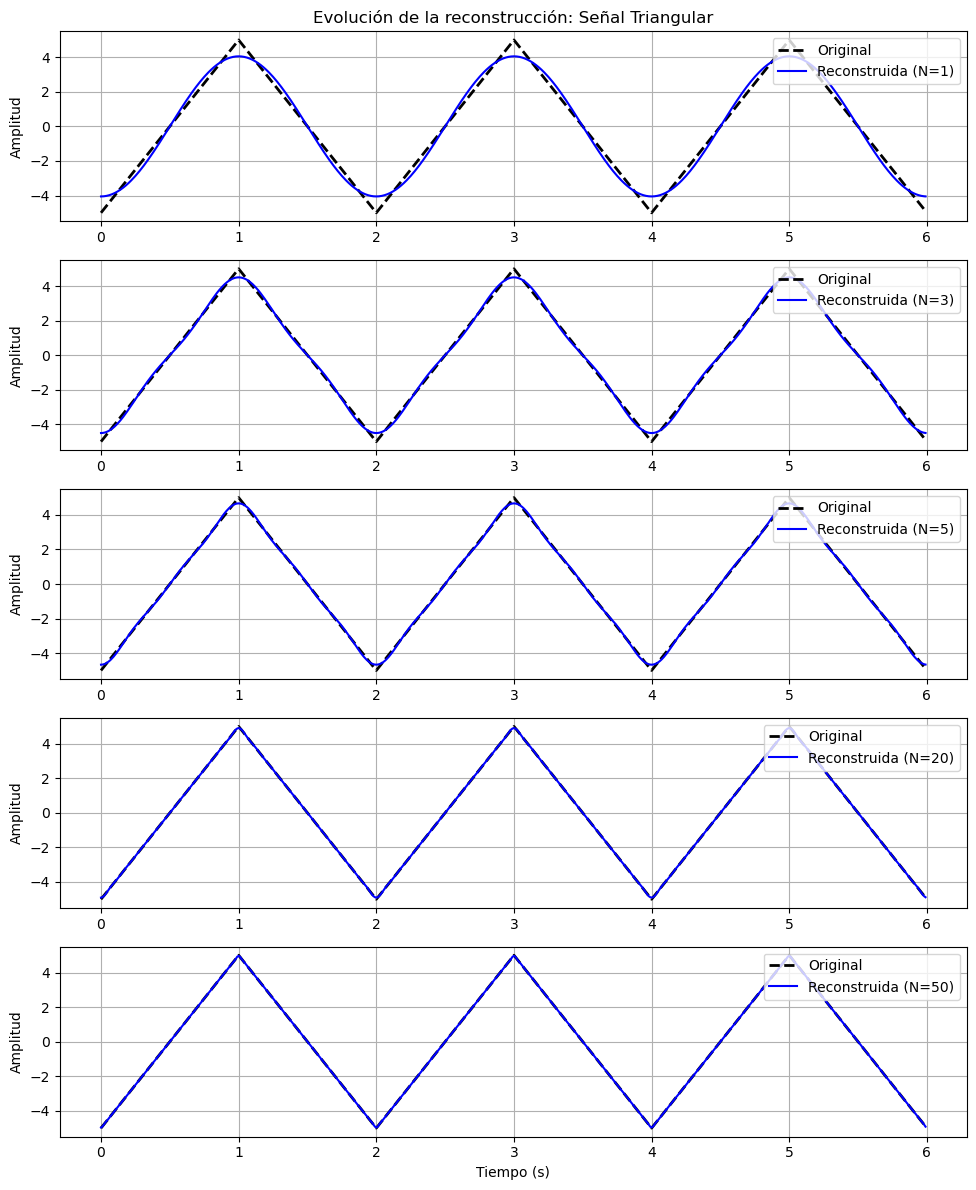

In [75]:
armonicos_evaluar = [1, 3, 5, 20, 50]

# Reconstrucción y gráfica para la Señal Cuadrada
plt.figure(figsize=(10, 12))
for i, n_arm in enumerate(armonicos_evaluar):

    # Reconstruimos usando la función del inciso anterior
    rec_cuadrada = reconstruir_senal(ck_cuadrada, n_arm, t, f0)
    
    # Creamos un subgráfico para cada valor de N
    plt.subplot(len(armonicos_evaluar), 1, i + 1)
    # Dibujamos la original en negro punteado
    plt.plot(t, senal_cuadrada, 'k--', linewidth=2, label='Original')
    # Dibujamos la reconstruida en rojo continuo
    plt.plot(t, rec_cuadrada, 'r-', linewidth=1.5, label=f'Reconstruida (N={n_arm})')
    
    plt.ylabel('Amplitud')
    plt.legend(loc='upper right')
    plt.grid(True)
    if i == 0:
        plt.title('Evolución de la reconstrucción: Señal Cuadrada')

plt.xlabel('Tiempo (s)')
plt.tight_layout()
plt.show()


# Reconstrucción y gráfica para la Señal Triangular
plt.figure(figsize=(10, 12))
for i, n_arm in enumerate(armonicos_evaluar):

    rec_triangular = reconstruir_senal(ck_triangular, n_arm, t, f0)
    

    plt.subplot(len(armonicos_evaluar), 1, i + 1)
    plt.plot(t, senal_triangular, 'k--', linewidth=2, label='Original')
    plt.plot(t, rec_triangular, 'b-', linewidth=1.5, label=f'Reconstruida (N={n_arm})')
    
    plt.ylabel('Amplitud')
    plt.legend(loc='upper right')
    plt.grid(True)
    if i == 0:
        plt.title('Evolución de la reconstrucción: Señal Triangular')

plt.xlabel('Tiempo (s)')
plt.tight_layout()
plt.show()